In [1]:
from reasoning_aware_irt.toy_scenarios import make_reasoning_aware_3pl_toy, build_scenarios

In [2]:
toy_list, names = build_scenarios()
print(names, len(toy_list))

['fail_budget_leverage_items', 'fail_budget_response', 'fail_confounding', 'fail_effective_rank', 'fail_fisher_proxy', 'fail_variance_ceiling', 'fail_variance_floor', 'pass_all'] 8


In [3]:
from reasoning_aware_irt.precondition_check import DataPreChecker
import numpy as np

avg_Y_list = [float(np.mean(t['Y_ij'])) for t in toy_list]

# results_list = []
passes = []
warns = []
all_results = {}
for i, toy in enumerate(toy_list):
    print('\n', names[i])
    chk = DataPreChecker(Y_ij=toy['Y_ij'], B_ij=toy['B_ij'], P_ij=toy.get('P_ij'))
    ok, warn, res = chk.run_all_tests()
    all_results[names[i]] = res
    # results_list.append(res)
    passes.append(ok)
    warns.append(warn)


print("passes:", passes)
print("warns:", warns)


 fail_budget_leverage_items
[PASS] Variance/Entropy: Items=0.74, Models=0.98
[PASS] Fisher Proxy: Items=0.1920, Models=0.2278
[FAIL] Budget Leverage: Items OK=0.20, Models OK=1.00
[PASS] Effective Rank=30.50, Ratio=0.94
[PASS] Ability-Budget Confounding Corr=-0.1017
[WARN] Budget-Response Association: Signal Prop=0.055 with threshold=0.23
[PASS] Budget-Response with PROB: Signal Prop=0.125 with threshold=0.23

 fail_budget_response
[PASS] Variance/Entropy: Items=0.81, Models=1.00
[PASS] Fisher Proxy: Items=0.1965, Models=0.2319
[PASS] Budget Leverage: Items OK=1.00, Models OK=1.00
[PASS] Effective Rank=46.16, Ratio=0.95
[PASS] Ability-Budget Confounding Corr=-0.0919
[PASS] Budget-Response Association: Signal Prop=0.120 with threshold=0.23
[PASS] Budget-Response with PROB: Signal Prop=0.105 with threshold=0.23

 fail_confounding
[PASS] Variance/Entropy: Items=0.74, Models=0.98
[PASS] Fisher Proxy: Items=0.1920, Models=0.2278
[PASS] Budget Leverage: Items OK=1.00, Models OK=1.00
[PASS] 

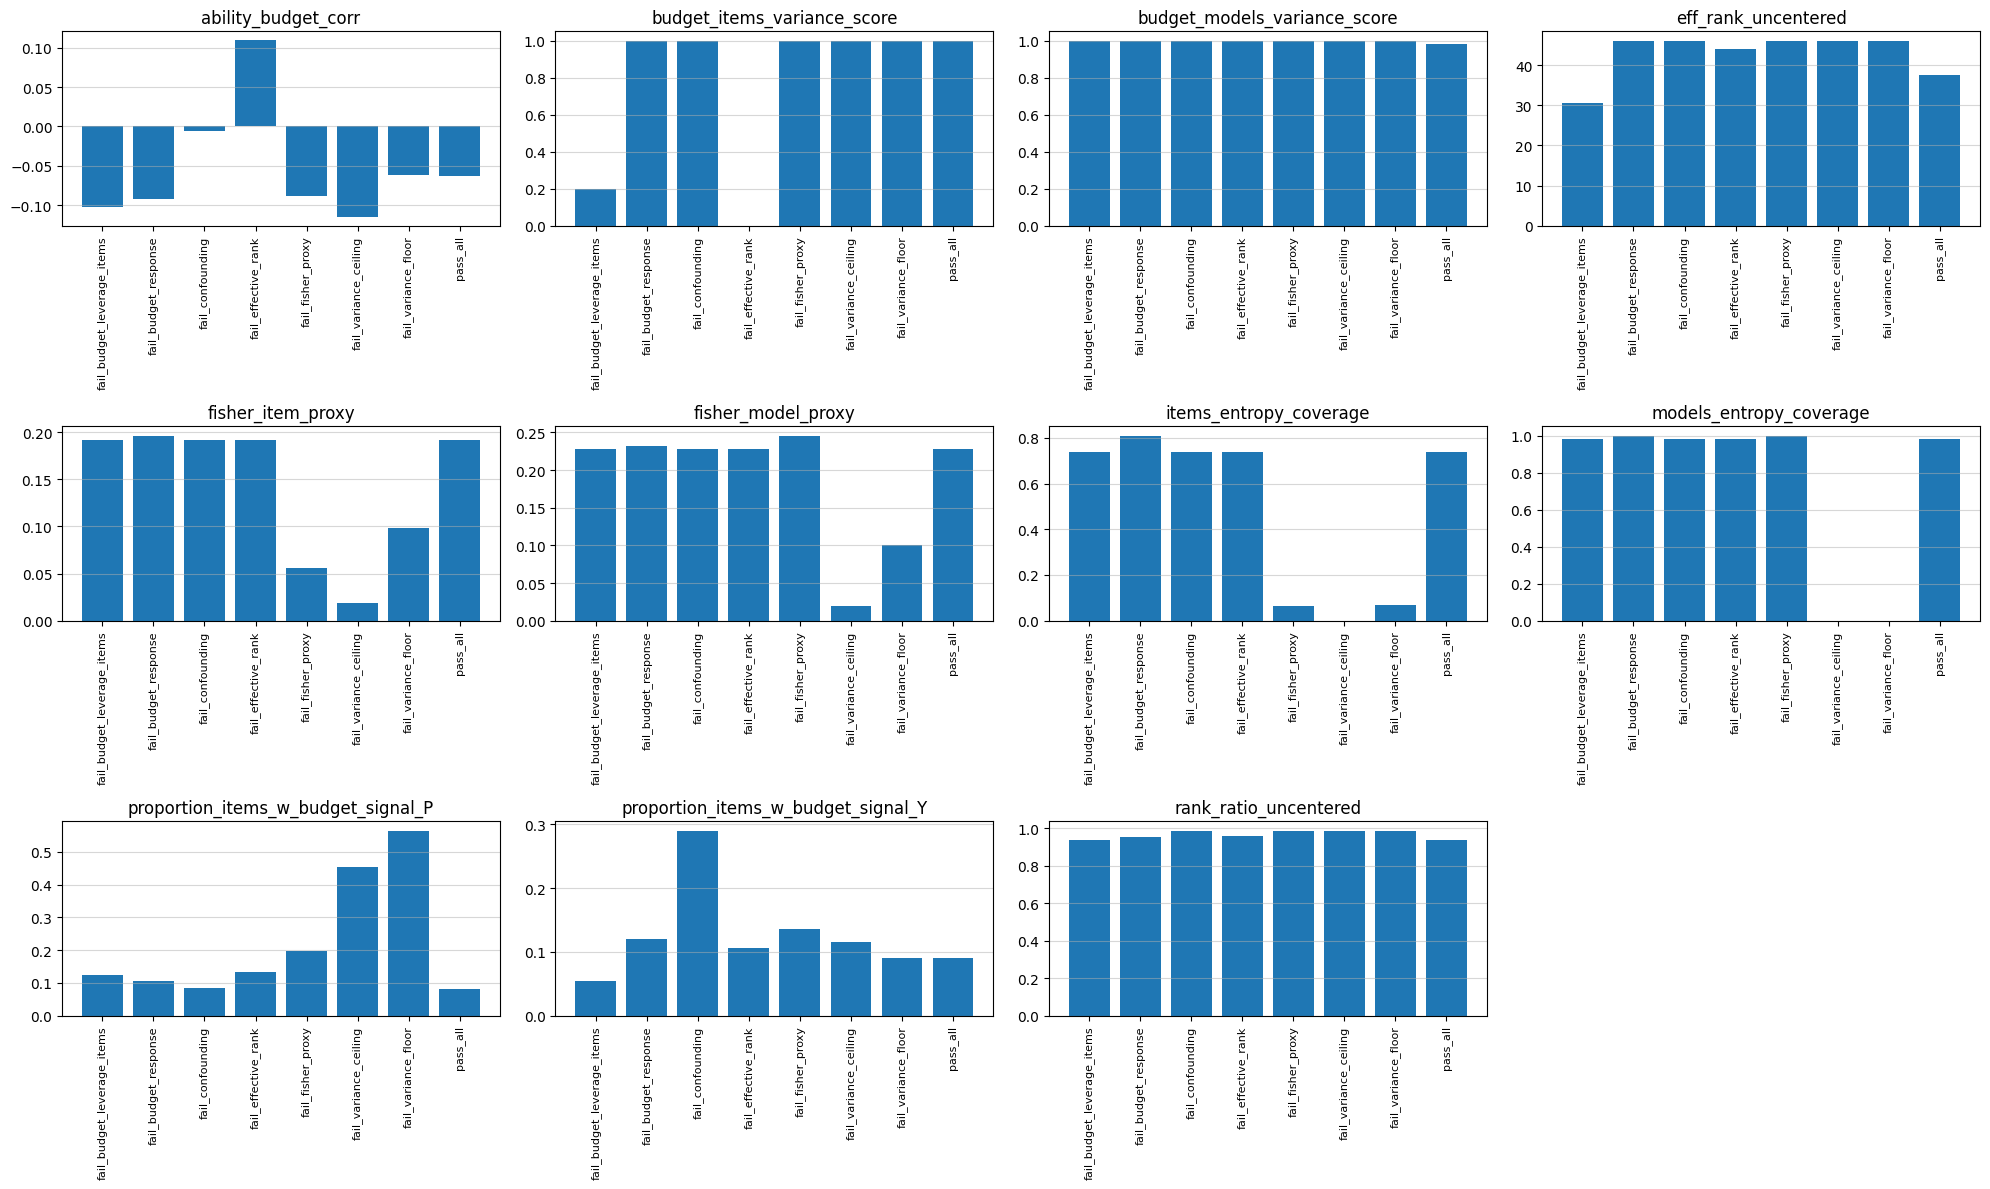

In [4]:
from reasoning_aware_irt.precondition_check import plot_precheck_results
import matplotlib.pyplot as plt
# fig, _ = plot_precheck_results(results_list, titles=names, avg_Y_list=avg_Y_list)
fig, _ = plot_precheck_results(all_results)
plt.show() # enable when running as a script

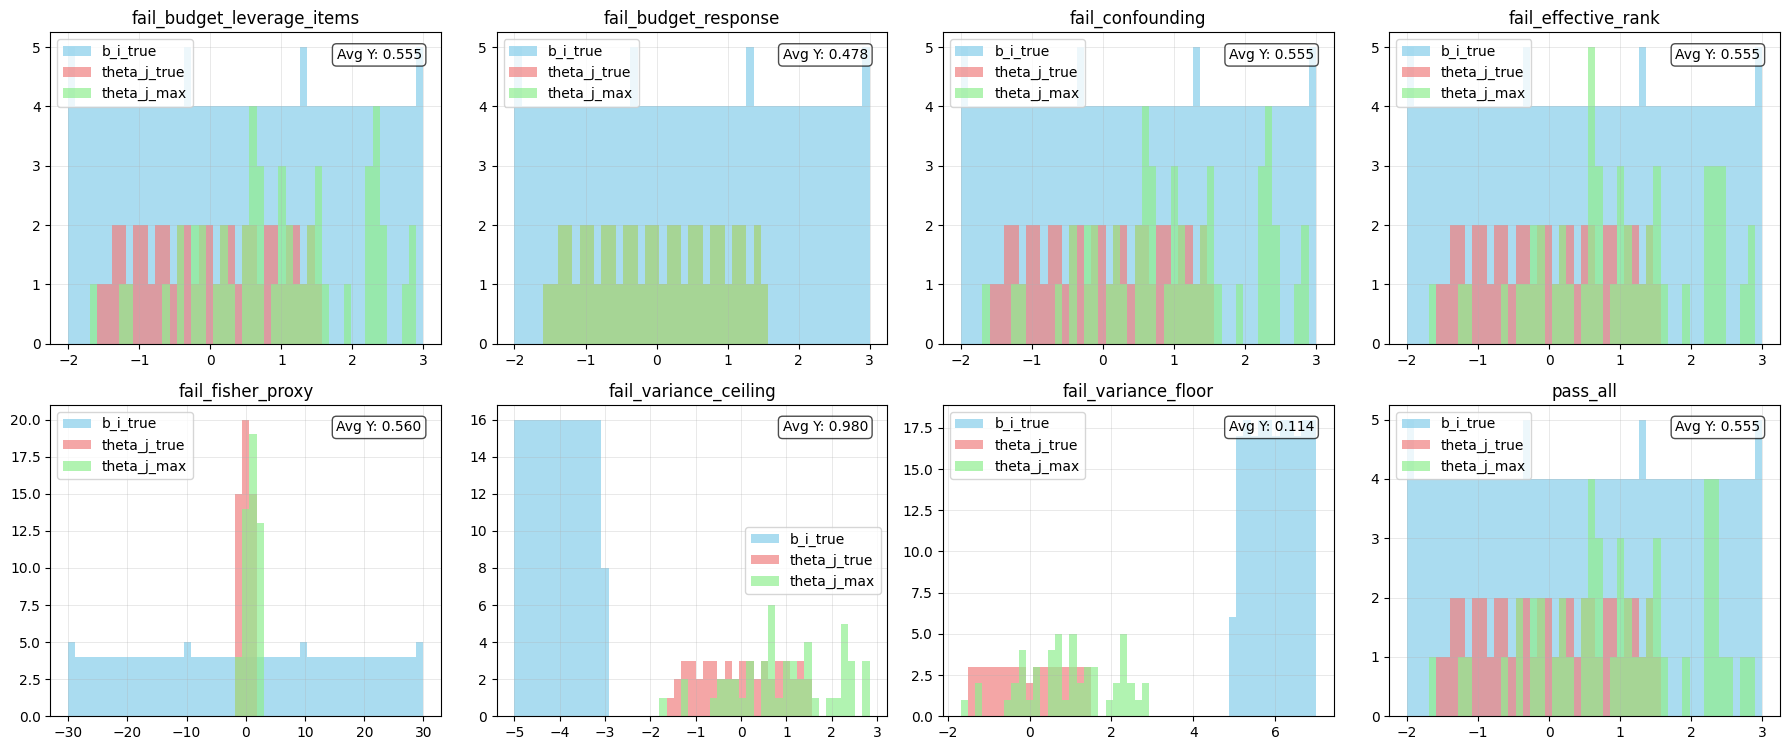

In [5]:
from reasoning_aware_irt.utils import plot_multiple_b_theta_histograms
_, _ = plot_multiple_b_theta_histograms(toy_list, names, plots_per_row=4, avg_Y_list=avg_Y_list)

# Systematic Check - varying #gate-on

In [ ]:
print_msg = False

b_span_list = np.linspace(-2.0, 5, 10)

toy_data_name_list, toy_data_list = [], []
all_results = []
avg_Y_list = []
for b_span in b_span_list:
    toy_data = make_reasoning_aware_3pl_toy(b_span_low=  b_span,
                                           b_span_high= b_span+1,
                                           frac_gate_on=1.0
                                           )
    toy_data_list.append(toy_data)
    toy_data_name_list.append(str(b_span))

    Y_mean = toy_data['Y_ij'].mean()
    avg_Y_list.append(Y_mean)

    if print_msg:
        print(f"\n--- RUNNING b_span: {b_span} ---")
        print(f"Average of Y = {Y_mean}")

    checker = DataPreChecker(Y_ij=toy_data['Y_ij'], B_ij=toy_data['B_ij'], P_ij=toy_data['P_ij'], print_msg=print_msg)
    ok, warn, results = checker.run_all_tests()
    all_results.append(results)

In [ ]:
_, _ = plot_multiple_b_theta_histograms(toy_data_list, toy_data_name_list, plots_per_row=4, avg_Y_list=avg_Y_list)

In [ ]:
_,_ = plot_precheck_results(all_results)

# Toy Data for GEM

0.45755


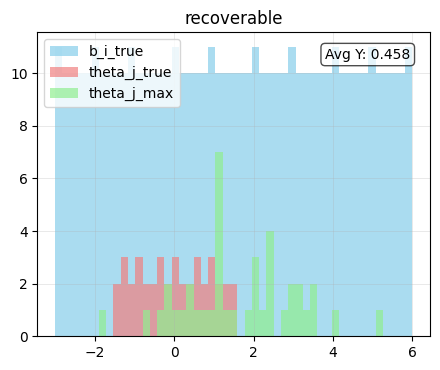

In [6]:
toy_data = make_reasoning_aware_3pl_toy(Q=500, c_val=0.001, 
                                        b_span_low=  -3, b_span_high= 6,frac_gate_on=0.999)

print(toy_data['Y_ij'].mean())
_, _ = plot_multiple_b_theta_histograms([toy_data], ['recoverable'], plots_per_row=2, avg_Y_list=[toy_data['Y_ij'].mean()])

8.881784197001253e-17 0.8879535677396305


/workspaces/reasoning-aware-irt/reasoning_aware_irt/utils.py:365: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


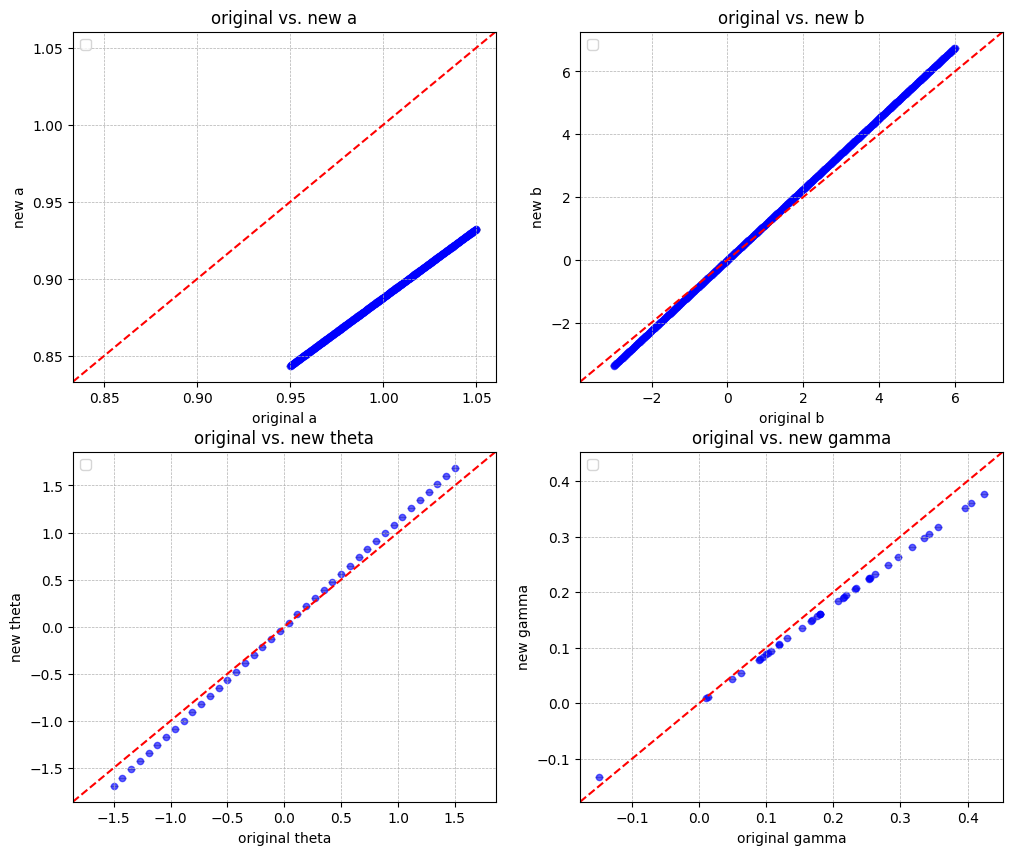

In [7]:
# """Investigate scale-location initialization variation"""
from reasoning_aware_irt.utils import plot_parameter_scatter_with_se, location_scale_transform

new_theta, mu, sigma = location_scale_transform(toy_data["theta_j_true"])
print(mu,sigma)

new_b, _, _ = location_scale_transform(toy_data["b_i_true"], mu, sigma)
new_a = toy_data["a_i_true"]*sigma
new_gamma = toy_data["gamma_j_true"]*sigma

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten() # Flatten the 2D array of axes for easy iteration
s = "a"
plot_parameter_scatter_with_se(axes[0], toy_data[f"{s}_i_true"], new_a, None, f"{s}", x_label=f"original {s}", y_label=f"new {s}", title=f"original vs. new {s}")
s = "b"
plot_parameter_scatter_with_se(axes[1], toy_data[f"{s}_i_true"], new_b, None, f"{s}", x_label=f"original {s}", y_label=f"new {s}", title=f"original vs. new {s}")
s = "theta"
plot_parameter_scatter_with_se(axes[2], toy_data[f"{s}_j_true"], new_theta, None, f"{s}", x_label=f"original {s}", y_label=f"new {s}", title=f"original vs. new {s}")
s = "gamma"
plot_parameter_scatter_with_se(axes[3], toy_data[f"{s}_j_true"], new_gamma, None, f"{s}", x_label=f"original {s}", y_label=f"new {s}", title=f"original vs. new {s}")


In [8]:
chk = DataPreChecker(Y_ij=toy_data['Y_ij'], B_ij=toy_data['B_ij'], P_ij=toy_data.get('P_ij'))
ok, warn, res = chk.run_all_tests()

[PASS] Variance/Entropy: Items=0.43, Models=1.00
[PASS] Fisher Proxy: Items=0.1320, Models=0.2327
[PASS] Budget Leverage: Items OK=1.00, Models OK=1.00
[PASS] Effective Rank=38.33, Ratio=0.99
[PASS] Ability-Budget Confounding Corr=-0.0666
[PASS] Budget-Response Association: Signal Prop=0.293 with threshold=0.26
[PASS] Budget-Response with PROB: Signal Prop=0.832 with threshold=0.26


## GEM

In [12]:
from reasoning_aware_irt.gem import CalibrationData, CalibrationConfig
from reasoning_aware_irt.gem import ReasoningAware3PLCalibrator

data = CalibrationData(Y_ij=toy_data["Y_ij"], B_ij=toy_data["B_ij"], c_i=toy_data["c_i_true"])
cfg = CalibrationConfig(
    gh_nodes=100, max_iter=200, verbose=True,
    ridge_lambda=10.0, ridge_gamma=10.0, ridge_a=5.0
)

calibrator = ReasoningAware3PLCalibrator(cfg)


In [10]:
from scipy.stats import spearmanr

theta_proxy = toy_data["Y_ij"].mean(axis=0)
b_proxy = 1 - toy_data["Y_ij"].mean(axis=1)

print("SIMPLE accuracy proxy's metrics : ")

spear_theta_proxy = spearmanr( toy_data["theta_j_true"], theta_proxy)
print('theta correlation:', np.corrcoef( toy_data["theta_j_true"], theta_proxy)[0,1])
print('theta spearman & pvalue:', spear_theta_proxy.statistic, spear_theta_proxy.pvalue)

spear_b_proxy = spearmanr( toy_data["b_i_true"], b_proxy)
print('b correlation:', np.corrcoef( toy_data["b_i_true"], b_proxy)[0,1])
print('b spearman & pvalue:', spear_b_proxy.statistic, spear_b_proxy.pvalue)

SIMPLE accuracy proxy's metrics : 
theta correlation: 0.8156931677653809
theta spearman & pvalue: 0.8256872163178467 5.492840695512966e-11
b correlation: 0.9762386616151001
b spearman & pvalue: 0.9814808649367579 0.0


In [13]:
fit_results = calibrator.fit(data)

mu_theta = -1.04, sigma_theta =  1.3076
iter   1  ll=-7090.581704   dLL=nan
mu_theta = -0.0217, sigma_theta =  0.91372
iter   2  ll=-6557.179491   dLL=nan
mu_theta = -0.0633, sigma_theta =  0.94745
iter   3  ll=-6499.593314   dLL=5.759e+01
mu_theta = -0.0561, sigma_theta =  0.96386
iter   4  ll=-6421.381766   dLL=7.821e+01
mu_theta = -0.0439, sigma_theta =  0.97742
iter   5  ll=-6382.155512   dLL=3.923e+01
mu_theta = -0.0295, sigma_theta =  0.98514
iter   6  ll=-6356.927511   dLL=2.523e+01
mu_theta = -0.0206, sigma_theta =  0.99206
iter   7  ll=-6339.554146   dLL=1.737e+01
mu_theta = -0.0155, sigma_theta =  0.99598
iter   8  ll=-6327.758328   dLL=1.180e+01
mu_theta = -0.0107, sigma_theta =  0.99785
iter   9  ll=-6319.039994   dLL=8.718e+00
mu_theta = -0.00624, sigma_theta =  1.0003
iter  10  ll=-6312.747672   dLL=6.292e+00
mu_theta = -0.00372, sigma_theta =  1.0026
iter  11  ll=-6308.111101   dLL=4.637e+00
mu_theta = -0.00291, sigma_theta =  1.0037
iter  12  ll=-6304.633082   dLL=3.478

## GEM Result analysis

In [14]:
#TODO: sum-sq. error instead of corrcoef (? we might need to also scale & location pin the true value)
print("Reasoning-Aware IRT's metrics : ")

print('theta correlation:', np.corrcoef( toy_data["theta_j_true"], fit_results.theta_j_mean)[0,1])
print('gamma correlation:', np.corrcoef( toy_data["gamma_j_true"], fit_results.gamma_j)[0,1])
print('b correlation:', np.corrcoef( toy_data["b_i_true"], fit_results.b_i)[0,1])
print('ratio of lambda > 0.6:', (fit_results.lambda_i > 0.6).sum()/ (fit_results.lambda_i.shape[0]))

spear_theta_gem = spearmanr( toy_data["theta_j_true"], fit_results.theta_j_mean)
print('theta spearman correlation & pvalue:', spear_theta_gem.statistic, spear_theta_gem.pvalue)
spear_b_gem = spearmanr( toy_data["b_i_true"], fit_results.b_i)
print('b spearman correlation & pvalue:', spear_b_gem.statistic, spear_b_gem.pvalue)

Reasoning-Aware IRT's metrics : 
theta correlation: 0.9468517876986877
gamma correlation: 0.9541869578883586
b correlation: 0.9400716987471635
ratio of lambda > 0.6: 0.99
theta spearman correlation & pvalue: 0.951031894934334 5.6654209605513945e-21
b spearman correlation & pvalue: 0.978751083004332 0.0


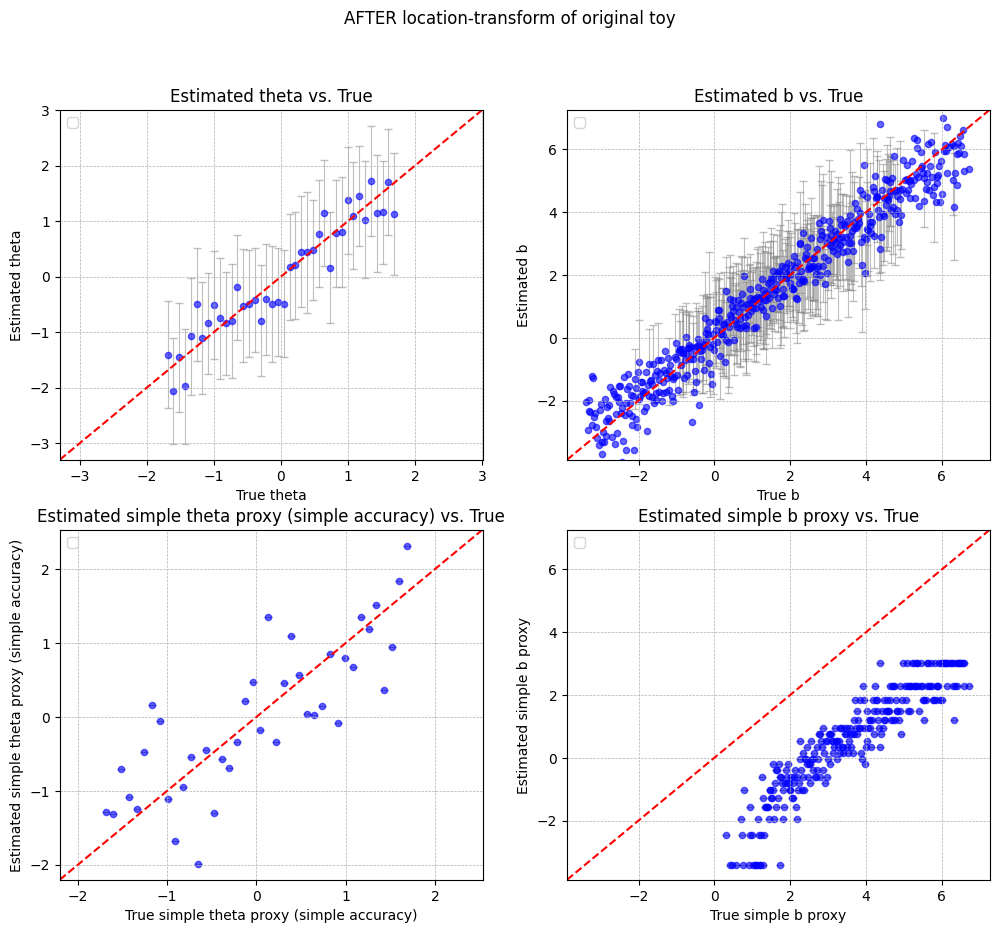

In [15]:
from reasoning_aware_irt.utils import plot_parameter_scatter_with_se
from scipy.special import logit

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle('AFTER location-transform of original toy')
axes = axes.flatten() # Flatten the 2D array of axes for easy iteration

theta_proxy_transform, mu_proxy, sigma_proxy = location_scale_transform(theta_proxy)
b_proxy_transform, _, _ = location_scale_transform(b_proxy, mu_proxy, sigma_proxy)
b_proxy_transform = logit(b_proxy_transform / np.max(np.abs(b_proxy_transform)))
# b_proxy_transform, _, _ = location_scale_transform(b_proxy_transform, mu_proxy, sigma_proxy)

plot_parameter_scatter_with_se(axes[0], new_theta, fit_results.theta_j_mean, fit_results.theta_bracket_half_tau, "theta")
plot_parameter_scatter_with_se(axes[1], new_b, fit_results.b_i, fit_results.b_bracket_half_tau, "b")
plot_parameter_scatter_with_se(axes[2], new_theta, theta_proxy_transform, None, "simple theta proxy (simple accuracy)")
plot_parameter_scatter_with_se(axes[3], new_b, b_proxy_transform, None, "simple b proxy")


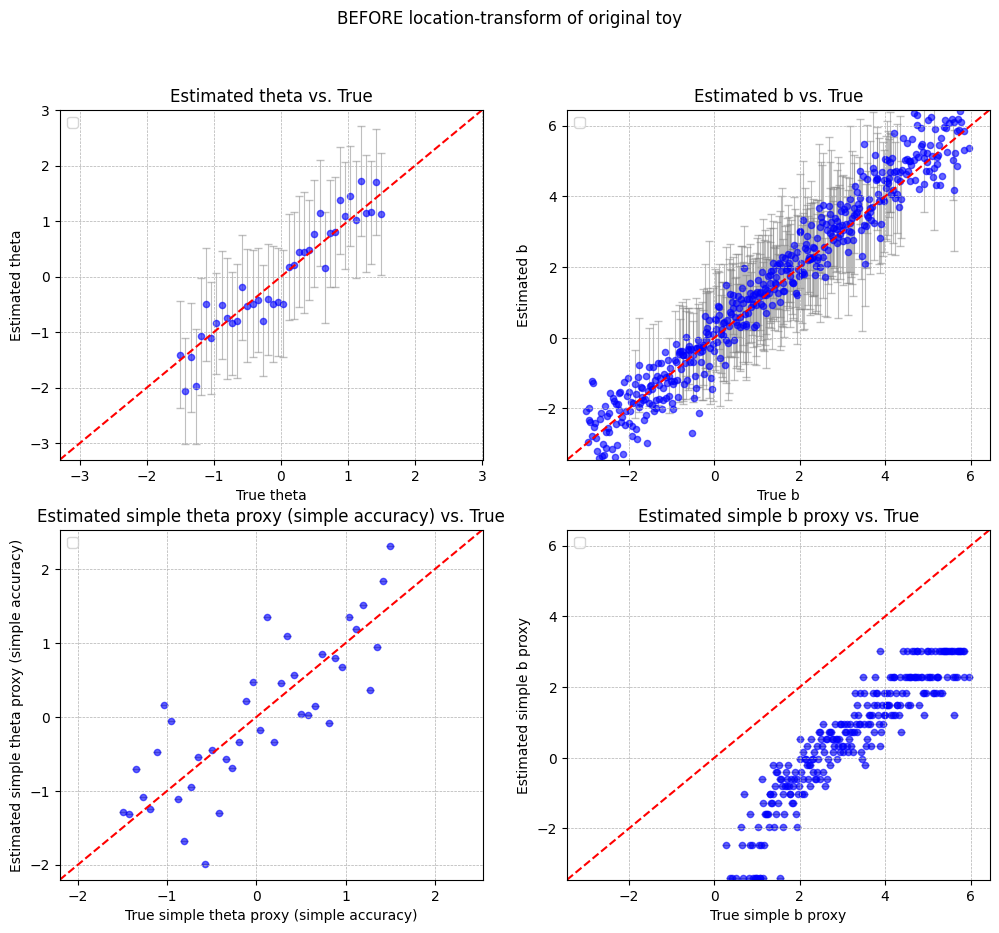

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten() # Flatten the 2D array of axes for easy iteration
fig.suptitle('BEFORE location-transform of original toy')

# pre location-transform of original toy
plot_parameter_scatter_with_se(axes[0], toy_data["theta_j_true"], fit_results.theta_j_mean, fit_results.theta_bracket_half_tau, "theta")
plot_parameter_scatter_with_se(axes[1], toy_data["b_i_true"], fit_results.b_i, fit_results.b_bracket_half_tau, "b")
plot_parameter_scatter_with_se(axes[2], toy_data["theta_j_true"], theta_proxy_transform, None, "simple theta proxy (simple accuracy)")
plot_parameter_scatter_with_se(axes[3], toy_data["b_i_true"], b_proxy_transform, None, "simple b proxy")



### Laplace-based SE

In [19]:
from reasoning_aware_irt.gem import compute_laplace_ses
ses = compute_laplace_ses(
        fit_results, data,
        blocks=("a","b","lambda","gamma"),
        ridges={"ridge_a":5,"ridge_b":1e-3,"ridge_lambda":10,"ridge_gamma":10},
    )

/workspaces/reasoning-aware-irt/reasoning_aware_irt/utils.py:365: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


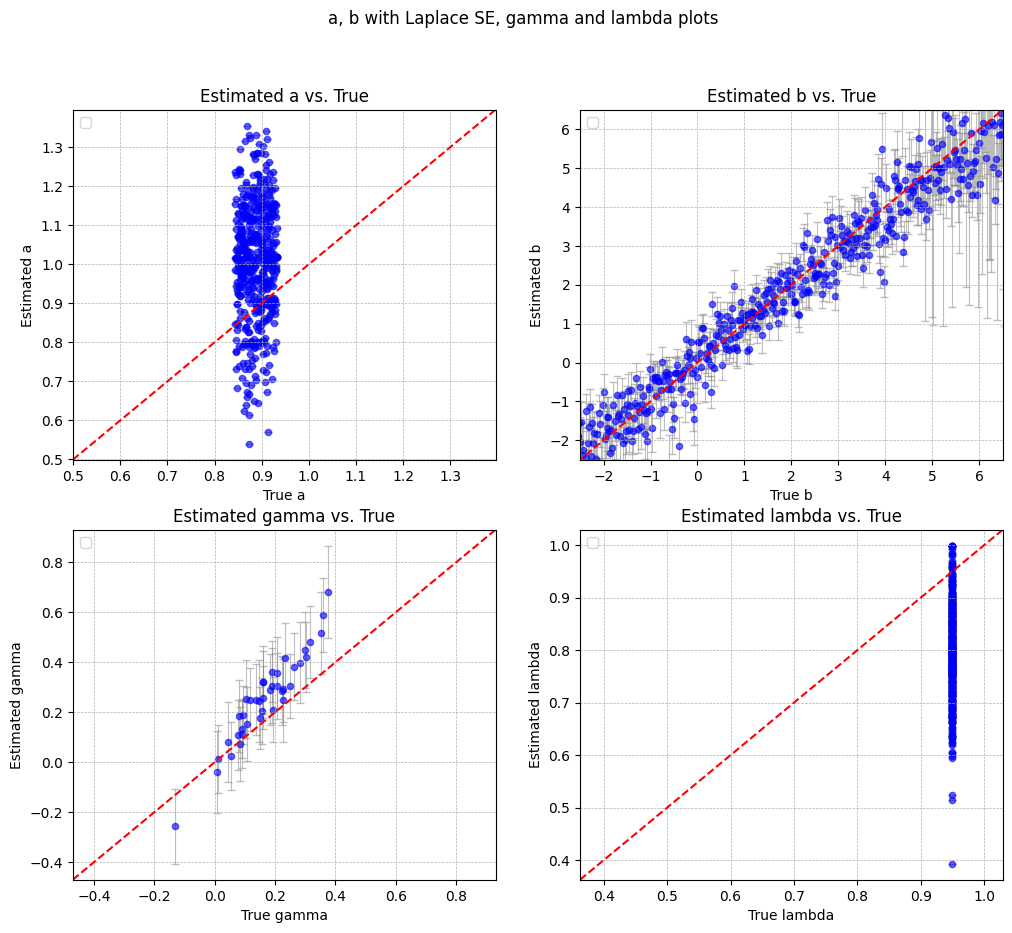

In [23]:
# VARIOUS other Info
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle('a, b with Laplace SE, gamma and lambda plots')
axes = axes.flatten() # Flatten the 2D array of axes for easy iteration

plot_parameter_scatter_with_se(axes[0], new_a, fit_results.a_i, None, "a") # ses["a_laplace_se"] is v.large
plot_parameter_scatter_with_se(axes[1], new_b, fit_results.b_i, ses["b_laplace_se"], "b", min_lim = -2.5, max_lim=6.5,)
plot_parameter_scatter_with_se(axes[2], new_gamma, fit_results.gamma_j, fit_results.gamma_bracket_half_tau, "gamma")

# original a, b, gamma BEFORE re-location/scale
# plot_parameter_scatter_with_se(axes[0], toy_data["a_i_true"], fit_results.a_i, None, "a") # ses["a_laplace_se"] is v.large
# plot_parameter_scatter_with_se(axes[1], toy_data["b_i_true"], fit_results.b_i, ses["b_laplace_se"], "b", min_lim = -2.5, max_lim=6.5)
# plot_parameter_scatter_with_se(axes[2], toy_data["gamma_j_true"], fit_results.gamma_j, fit_results.gamma_bracket_half_tau, "gamma")
# plot_parameter_scatter_with_se(axes[2], toy_data["gamma_j_true"], fit_results.gamma_j, ses["gamma_laplace_se"], "gamma")

plot_parameter_scatter_with_se(axes[3], toy_data["lambda_i_true"], fit_results.lambda_i, None, "lambda")

# Macro Information Function

In [ ]:
from reasoning_aware_irt.utils import create_test_information_figure, create_item_information_figure, plot_test_characteristic_curve

item_indices_to_plot = [0, 10, 99, 149, 199]
item_names = [str(i) for i in item_indices_to_plot]

a = np.array([toy_list[-1]['a_i_true'][i] for i in item_indices_to_plot])
b = np.array([toy_list[-1]['b_i_true'][i] for i in item_indices_to_plot])
c = np.array([toy_list[-1]['c_i_true'][i] for i in item_indices_to_plot])

fig = create_test_information_figure(a,b,c,item_names)


In [ ]:
fig.show()

In [ ]:
item_indices_to_plot = [0, 10, 99, 149, 199]
item_names = [str(i) for i in item_indices_to_plot]

a = np.array([toy_list[-1]['a_i_true'][i] for i in item_indices_to_plot])
b = np.array([toy_list[-1]['b_i_true'][i] for i in item_indices_to_plot])
c = np.array([toy_list[-1]['c_i_true'][i] for i in item_indices_to_plot])

fig = create_item_information_figure(a,b,c,item_names)
fig.show()

In [ ]:
fig = plot_test_characteristic_curve(toy_data_list[2])
fig.show()